# 26SU-5: LTE-Limited Analytic Velocity Contour

Visualizes the latest adaptive hydro-analytic cluster result from `new_paper_calculations/26-06-07`.

## Load Latest LTE Result

Loads the corrected cluster payload and checks that it contains the LTE boundary and finite velocity data.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

DATA_PATH = Path("new_paper_calculations/26-06-07/hydro-analytic-LTE-adaptive-contour__adaptive_v1.npy")
OUTPUT_DIR = Path("local_analysis_results/26SU-5")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Missing LTE analytic payload: {DATA_PATH}")

payload = np.load(DATA_PATH, allow_pickle=True).item()
velocity_grid = np.asarray(payload["velocity_grid_m_s"], dtype=float)
finite_velocity = np.isfinite(velocity_grid) & (velocity_grid > 0.0)

if payload.get("boundary_semantics") != "aQstar_LTE = 1":
    raise RuntimeError(f"Unexpected boundary semantics: {payload.get('boundary_semantics')!r}")
if not np.any(finite_velocity):
    raise RuntimeError("The selected payload contains no finite positive velocities")

ncrit_over_n0 = float(payload["nB_crit"] / payload["n0"])
print(f"Loaded: {DATA_PATH}")
print(f"Finite velocity points: {int(finite_velocity.sum())}/{velocity_grid.size}")
print(f"Velocity range: {velocity_grid[finite_velocity].min():.6g} to {velocity_grid[finite_velocity].max():.6g} m/s")
print(f"Boundary: {payload['boundary_semantics']}")

Loaded: new_paper_calculations/26-06-07/hydro-analytic-LTE-adaptive-contour__adaptive_v1.npy
Finite velocity points: 5242/5250
Velocity range: 17.4156 to 51397.7 m/s
Boundary: aQstar_LTE = 1


## LTE-Limited Analytic Contour

The gray region lies above the saved \(a_{Q^*}^{\rm LTE}=1\) boundary. Plot levels, colors, fonts, limits, and label positions are editable at the beginning of the cell.

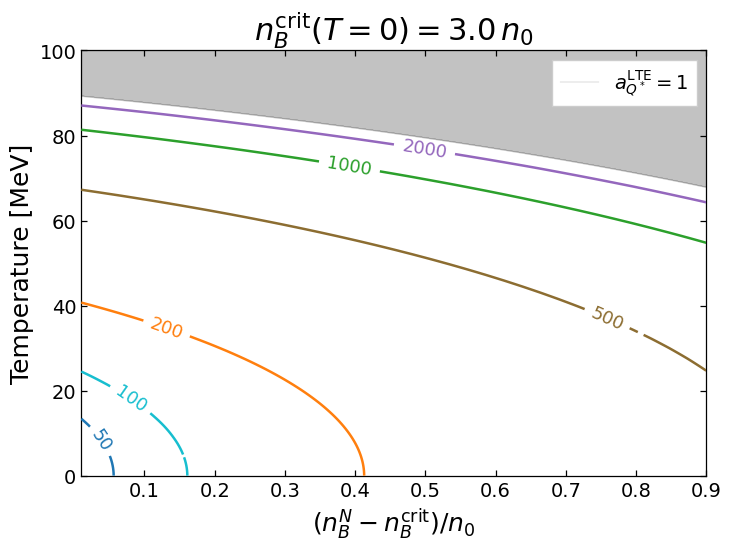

Saved local_analysis_results/26SU-5/26SU-5-hydro-analytic-LTE-adaptive-contour.png
Saved local_analysis_results/26SU-5/26SU-5-hydro-analytic-LTE-adaptive-contour.pdf


In [3]:
# Editable plot controls
FIGSIZE = (7.2, 5.4)
X_LIMITS = (0.01, 0.9)
Y_LIMITS = (0.0, 100.0)
CONTOUR_LEVELS = [50, 100, 200, 500, 1000, 2000]
CONTOUR_COLORS = ["#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#9467bd"]
CONTOUR_CMAP = None  # Set to a Matplotlib cmap name and set CONTOUR_COLORS = None to use it.
CONTOUR_LINEWIDTH = 1.8
BOUNDARY_LINEWIDTH = 0.1
SHADE_COLOR = "0.72"
SHADE_ALPHA = 0.85
TITLE_FONTSIZE = 22
AXIS_LABEL_FONTSIZE = 18
TICK_FONTSIZE = 14
CONTOUR_LABEL_FONTSIZE = 13
LEGEND_FONTSIZE = 14
MANUAL_LABEL_POSITIONS = [
    (0.035, 8.0),
    (0.080, 18.0),
    (0.130, 34.0),
    (0.745, 32.0),
    (0.390, 71.0),
    (0.500, 78.0),
]

M = np.asarray(payload["metastability_grid"], dtype=float)
T = np.asarray(payload["temperature_grid"], dtype=float)
V = np.asarray(payload["velocity_grid_m_s"], dtype=float)
boundary_m = np.asarray(payload["boundary_metastability_values"], dtype=float)
boundary_T = np.asarray(payload["boundary_temperature_values"], dtype=float)

finite = np.isfinite(M) & np.isfinite(T) & np.isfinite(V) & (V > 0.0)
finite_boundary = np.isfinite(boundary_m) & np.isfinite(boundary_T)
boundary_order = np.argsort(boundary_m[finite_boundary])
boundary_m = boundary_m[finite_boundary][boundary_order]
boundary_T = boundary_T[finite_boundary][boundary_order]

available_levels = [
    float(level)
    for level in CONTOUR_LEVELS
    if np.nanmin(V[finite]) <= float(level) <= np.nanmax(V[finite])
]
if CONTOUR_COLORS is not None:
    level_to_color = dict(zip(CONTOUR_LEVELS, CONTOUR_COLORS))
    contour_colors = [level_to_color[level] for level in available_levels]
else:
    contour_colors = None

fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True, facecolor="white")
ax.set_facecolor("white")
ax.fill_between(
    boundary_m,
    boundary_T,
    Y_LIMITS[1],
    color=SHADE_COLOR,
    alpha=SHADE_ALPHA,
    zorder=0,
)
ax.plot(
    boundary_m,
    boundary_T,
    color="black",
    lw=BOUNDARY_LINEWIDTH,
    label=r"$a_{Q^*}^{\rm LTE}=1$",
    zorder=4,
)

masked_V = np.ma.masked_where(~finite, V)
contour = ax.contour(
    M,
    T,
    masked_V,
    levels=available_levels,
    colors=contour_colors,
    cmap=None if contour_colors is not None else CONTOUR_CMAP,
    linewidths=CONTOUR_LINEWIDTH,
    zorder=3,
)
ax.clabel(
    contour,
    contour.levels,
    manual=MANUAL_LABEL_POSITIONS,
    inline=True,
    inline_spacing=5,
    fontsize=CONTOUR_LABEL_FONTSIZE,
    fmt=lambda value: f"{value:.0f}",
)

ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel(r"$(n_B^N-n_B^{\rm crit})/n_0$", fontsize=AXIS_LABEL_FONTSIZE)
ax.set_ylabel("Temperature [MeV]", fontsize=AXIS_LABEL_FONTSIZE)
ax.set_title(
    rf"$n_B^{{\rm crit}}(T=0)={ncrit_over_n0:.1f}\,n_0$",
    fontsize=TITLE_FONTSIZE,
    pad=8,
)
ax.tick_params(
    direction="in",
    top=True,
    right=True,
    length=4.0,
    width=0.9,
    labelsize=TICK_FONTSIZE,
)
for spine in ax.spines.values():
    spine.set_linewidth(0.9)
ax.legend(
    loc="upper right",
    fontsize=LEGEND_FONTSIZE,
    frameon=True,
    fancybox=False,
    framealpha=1.0,
)

png_path = OUTPUT_DIR / "26SU-5-hydro-analytic-LTE-adaptive-contour.png"
pdf_path = OUTPUT_DIR / "26SU-5-hydro-analytic-LTE-adaptive-contour.pdf"
fig.savefig(png_path, dpi=240, facecolor="white")
fig.savefig(pdf_path, facecolor="white")
plt.show()
print(f"Saved {png_path}")
print(f"Saved {pdf_path}")

## Load Comparison Results

Loads the numerical \(u_N^{\max}\), LTE-limited analytic, and legacy extreme-endothermic adaptive payloads and checks that they use the same critical density and bag constant.

In [4]:
NUMERICAL_PATH = Path("new_paper_calculations/26-06-01/26SU-2-hydro-numerical-uNmax-adaptive-contour__numerical_uNmax_v1.npy")
LTE_PATH = DATA_PATH
EXTREME_PATH = Path("local_analysis_results/22May/state_of_art/26SU-2-hydro-analytic-adaptive-contour__adaptive_v1.npy")

comparison_paths = {
    "numerical": NUMERICAL_PATH,
    "LTE": LTE_PATH,
    "extreme_endothermic": EXTREME_PATH,
}
for name, path in comparison_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name} payload: {path}")

comparison_payloads = {
    name: np.load(path, allow_pickle=True).item()
    for name, path in comparison_paths.items()
}

reference_ncrit = float(comparison_payloads["LTE"]["nB_crit"] / comparison_payloads["LTE"]["n0"])
reference_B14 = float(comparison_payloads["LTE"]["B14"])
for name, result in comparison_payloads.items():
    ncrit_value = float(result["nB_crit"] / result["n0"])
    B14_value = float(result["B14"])
    if not np.isclose(ncrit_value, reference_ncrit, rtol=0.0, atol=1.0e-12):
        raise RuntimeError(f"{name} uses nB_crit/n0={ncrit_value}, expected {reference_ncrit}")
    if not np.isclose(B14_value, reference_B14, rtol=0.0, atol=1.0e-8):
        raise RuntimeError(f"{name} uses B^(1/4)={B14_value}, expected {reference_B14}")
    values = np.asarray(result["velocity_grid_m_s"], dtype=float)
    finite_values = np.isfinite(values) & (values > 0.0)
    print(
        f"{name:22s}: {int(finite_values.sum()):4d} finite points, "
        f"{values[finite_values].min():.4g} to {values[finite_values].max():.4g} m/s"
    )

numerical             : 1877 finite points, 33.24 to 709.4 m/s
LTE                   : 5242 finite points, 17.42 to 5.14e+04 m/s
extreme_endothermic   : 5242 finite points, 18.35 to 5.265e+04 m/s


## Three-Panel Contour Comparison

Uses the same velocity levels and colors in every panel. Each panel uses its own saved adaptive grid and boundary.

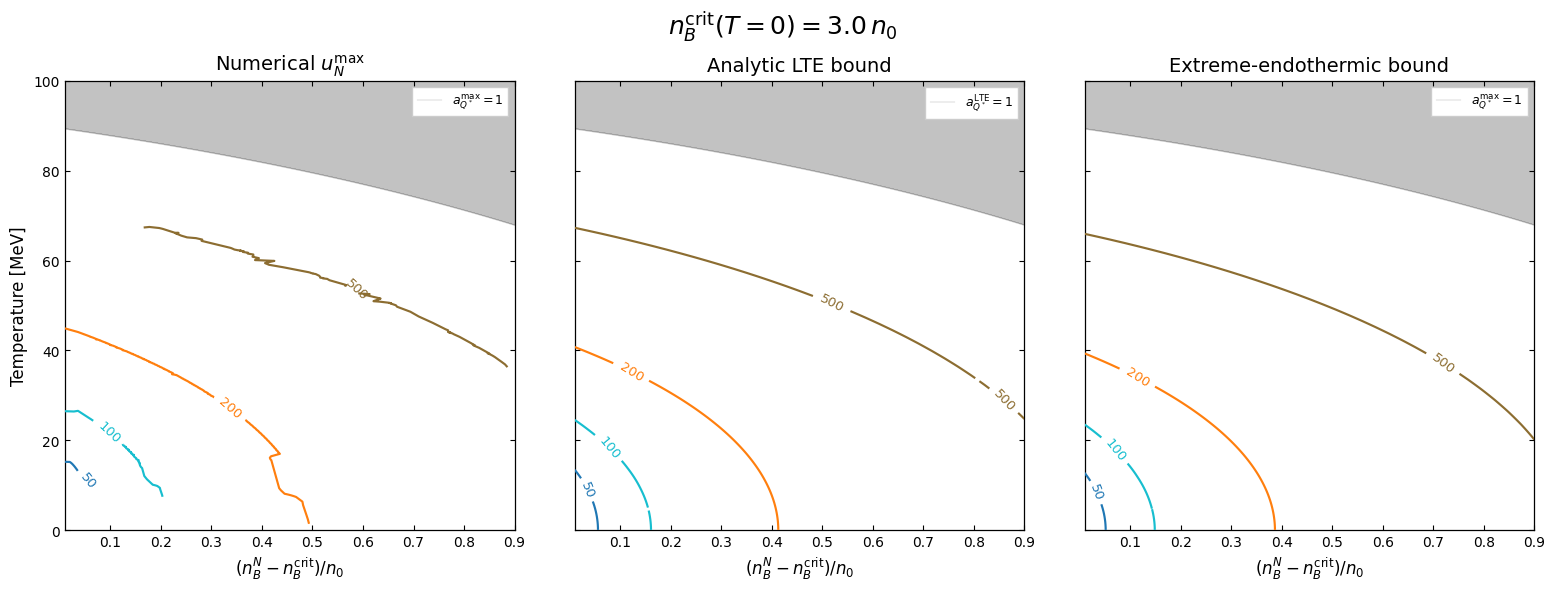

Saved local_analysis_results/26SU-5/26SU-5-three-way-contour-comparison.png
Saved local_analysis_results/26SU-5/26SU-5-three-way-contour-comparison.pdf


In [5]:
# Editable three-panel comparison controls
COMPARISON_LEVELS = [50, 100, 200, 500]
COMPARISON_COLORS = ["#1f77b4", "#17becf", "#ff7f0e", "#8c6d31"]
COMPARISON_FIGSIZE = (15.6, 5.8)
COMPARISON_CONTOUR_LINEWIDTH = 1.55
COMPARISON_BOUNDARY_LINEWIDTH = 0.1
COMPARISON_SHADE_COLOR = "0.72"
COMPARISON_SHADE_ALPHA = 0.85
COMPARISON_TITLE_FONTSIZE = 14
COMPARISON_LABEL_FONTSIZE = 12
COMPARISON_TICK_FONTSIZE = 10
COMPARISON_CONTOUR_LABEL_FONTSIZE = 9.5


def _comparison_grid(result):
    M_local = np.asarray(result["metastability_grid"], dtype=float)
    T_local = np.asarray(result["temperature_grid"], dtype=float)
    V_local = np.asarray(result["velocity_grid_m_s"], dtype=float)
    finite_local = np.isfinite(M_local) & np.isfinite(T_local) & np.isfinite(V_local) & (V_local > 0.0)
    return M_local, T_local, V_local, finite_local


def _comparison_boundary(result):
    m_local = np.asarray(result["boundary_metastability_values"], dtype=float)
    T_local = np.asarray(result["boundary_temperature_values"], dtype=float)
    finite_local = np.isfinite(m_local) & np.isfinite(T_local)
    order_local = np.argsort(m_local[finite_local])
    return m_local[finite_local][order_local], T_local[finite_local][order_local]


def _draw_comparison_panel(ax, result, title, boundary_label, use_tricontour=False):
    M_local, T_local, V_local, finite_local = _comparison_grid(result)
    boundary_m_local, boundary_T_local = _comparison_boundary(result)
    available = [
        float(level)
        for level in COMPARISON_LEVELS
        if np.nanmin(V_local[finite_local]) <= float(level) <= np.nanmax(V_local[finite_local])
    ]
    color_map = dict(zip(COMPARISON_LEVELS, COMPARISON_COLORS))
    colors_local = [color_map[level] for level in available]

    ax.set_facecolor("white")
    ax.fill_between(
        boundary_m_local,
        boundary_T_local,
        Y_LIMITS[1],
        color=COMPARISON_SHADE_COLOR,
        alpha=COMPARISON_SHADE_ALPHA,
        zorder=0,
    )
    ax.plot(
        boundary_m_local,
        boundary_T_local,
        color="black",
        lw=COMPARISON_BOUNDARY_LINEWIDTH,
        label=boundary_label,
        zorder=4,
    )

    if use_tricontour:
        contour_local = ax.tricontour(
            M_local[finite_local],
            T_local[finite_local],
            V_local[finite_local],
            levels=available,
            colors=colors_local,
            linewidths=COMPARISON_CONTOUR_LINEWIDTH,
            zorder=3,
        )
    else:
        masked_local = np.ma.masked_where(~finite_local, V_local)
        contour_local = ax.contour(
            M_local,
            T_local,
            masked_local,
            levels=available,
            colors=colors_local,
            linewidths=COMPARISON_CONTOUR_LINEWIDTH,
            zorder=3,
        )
    ax.clabel(
        contour_local,
        contour_local.levels,
        inline=True,
        inline_spacing=4,
        fontsize=COMPARISON_CONTOUR_LABEL_FONTSIZE,
        fmt=lambda value: f"{value:.0f}",
    )
    ax.set_xlim(*X_LIMITS)
    ax.set_ylim(*Y_LIMITS)
    ax.set_box_aspect(1)
    ax.set_xlabel(r"$(n_B^N-n_B^{\rm crit})/n_0$", fontsize=COMPARISON_LABEL_FONTSIZE)
    ax.set_title(title, fontsize=COMPARISON_TITLE_FONTSIZE, pad=7)
    ax.tick_params(
        direction="in",
        top=True,
        right=True,
        length=3.5,
        width=0.8,
        labelsize=COMPARISON_TICK_FONTSIZE,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(0.9)
    ax.legend(loc="upper right", fontsize=9, frameon=True, fancybox=False, framealpha=1.0)


fig, axes = plt.subplots(
    1,
    3,
    figsize=COMPARISON_FIGSIZE,
    sharex=True,
    sharey=True,
    constrained_layout=True,
    facecolor="white",
)
_draw_comparison_panel(
    axes[0],
    comparison_payloads["numerical"],
    r"Numerical $u_N^{\max}$",
    r"$a_{Q^*}^{\max}=1$",
    use_tricontour=True,
)
_draw_comparison_panel(
    axes[1],
    comparison_payloads["LTE"],
    r"Analytic LTE bound",
    r"$a_{Q^*}^{\rm LTE}=1$",
)
_draw_comparison_panel(
    axes[2],
    comparison_payloads["extreme_endothermic"],
    r"Extreme-endothermic bound",
    r"$a_{Q^*}^{\max}=1$",
)
axes[0].set_ylabel("Temperature [MeV]", fontsize=COMPARISON_LABEL_FONTSIZE)
fig.suptitle(
    rf"$n_B^{{\rm crit}}(T=0)={reference_ncrit:.1f}\,n_0$",
    fontsize=18,
)

comparison_png = OUTPUT_DIR / "26SU-5-three-way-contour-comparison.png"
comparison_pdf = OUTPUT_DIR / "26SU-5-three-way-contour-comparison.pdf"
fig.savefig(comparison_png, dpi=240, facecolor="white")
fig.savefig(comparison_pdf, facecolor="white")
plt.show()
print(f"Saved {comparison_png}")
print(f"Saved {comparison_pdf}")

## Overlaid Three-Way Comparison

Colors identify velocity levels. Line styles identify the calculation: solid for LTE analytic, dashed for extreme-endothermic analytic, and dotted for numerical \(u_N^{\max}\).

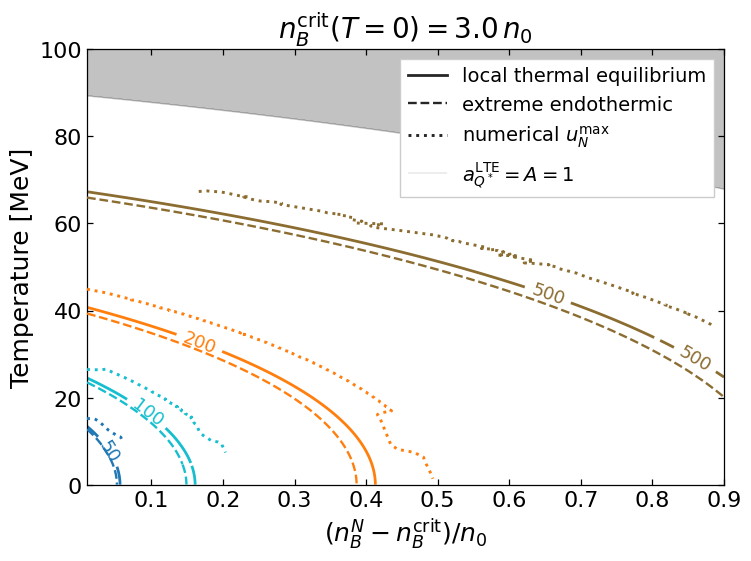

Saved local_analysis_results/26SU-5/26SU-5-three-way-contour-overlay.png
Saved local_analysis_results/26SU-5/LTE_integrated.pdf


In [11]:
from matplotlib.lines import Line2D

# Editable overlay controls
OVERLAY_LEVELS = [50, 100, 200, 500]
OVERLAY_COLORS = ["#1f77b4", "#17becf", "#ff7f0e", "#8c6d31"]
OVERLAY_STYLES = {
    "LTE": "-",
    "extreme_endothermic": "--",
    "numerical": ":",
}
OVERLAY_WIDTHS = {
    "LTE": 2.0,
    "extreme_endothermic": 1.7,
    "numerical": 2.1,
}
OVERLAY_FIGSIZE = (7.4, 5.5)
OVERLAY_BOUNDARY_LINEWIDTH = 0.1

fig, ax = plt.subplots(figsize=OVERLAY_FIGSIZE, constrained_layout=True, facecolor="white")
ax.set_facecolor("white")
boundary_m_overlay, boundary_T_overlay = _comparison_boundary(comparison_payloads["LTE"])
ax.fill_between(
    boundary_m_overlay,
    boundary_T_overlay,
    Y_LIMITS[1],
    color=COMPARISON_SHADE_COLOR,
    alpha=COMPARISON_SHADE_ALPHA,
    zorder=0,
)
ax.plot(
    boundary_m_overlay,
    boundary_T_overlay,
    color="black",
    lw=OVERLAY_BOUNDARY_LINEWIDTH,
    zorder=5,
)

overlay_contours = {}
overlay_order = ["LTE", "extreme_endothermic", "numerical"]
for zorder_value, name in enumerate(overlay_order, start=2):
    result = comparison_payloads[name]
    M_local, T_local, V_local, finite_local = _comparison_grid(result)
    available = [
        float(level)
        for level in OVERLAY_LEVELS
        if np.nanmin(V_local[finite_local]) <= float(level) <= np.nanmax(V_local[finite_local])
    ]
    color_map = dict(zip(OVERLAY_LEVELS, OVERLAY_COLORS))
    colors_local = [color_map[level] for level in available]
    if name == "numerical":
        contour_local = ax.tricontour(
            M_local[finite_local],
            T_local[finite_local],
            V_local[finite_local],
            levels=available,
            colors=colors_local,
            linestyles=OVERLAY_STYLES[name],
            linewidths=OVERLAY_WIDTHS[name],
            zorder=zorder_value,
        )
    else:
        masked_local = np.ma.masked_where(~finite_local, V_local)
        contour_local = ax.contour(
            M_local,
            T_local,
            masked_local,
            levels=available,
            colors=colors_local,
            linestyles=OVERLAY_STYLES[name],
            linewidths=OVERLAY_WIDTHS[name],
            zorder=zorder_value,
        )
    overlay_contours[name] = contour_local

# Label only the solid LTE contours to keep the overlay legible.
ax.clabel(
    overlay_contours["LTE"],
    overlay_contours["LTE"].levels,
    inline=True,
    inline_spacing=5,
    fontsize=13,
    fmt=lambda value: f"{value:.0f}",
)

method_handles = [
    Line2D([0], [0], color="0.15", lw=OVERLAY_WIDTHS["LTE"], ls=OVERLAY_STYLES["LTE"], label="local thermal equilibrium"),
    Line2D([0], [0], color="0.15", lw=OVERLAY_WIDTHS["extreme_endothermic"], ls=OVERLAY_STYLES["extreme_endothermic"], label="extreme endothermic"),
    Line2D([0], [0], color="0.15", lw=OVERLAY_WIDTHS["numerical"], ls=OVERLAY_STYLES["numerical"], label=r"numerical $u_N^{\max}$"),
    Line2D([0], [0], color="black", lw=OVERLAY_BOUNDARY_LINEWIDTH, ls="-", label=r"$a_{Q^*}^{\rm LTE} = A = 1$"),
]
ax.legend(handles=method_handles, loc="upper right", fontsize=14, frameon=True, fancybox=False, framealpha=1.0)
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel(r"$(n_B^N-n_B^{\rm crit})/n_0$", fontsize=18)
ax.set_ylabel("Temperature [MeV]", fontsize=18)
ax.set_title(
    rf"$n_B^{{\rm crit}}(T=0)={reference_ncrit:.1f}\,n_0$",
    fontsize=20,
    pad=8,
)
ax.tick_params(direction="in", top=True, right=True, length=4.0, width=0.9, labelsize=16)
for spine in ax.spines.values():
    spine.set_linewidth(0.9)

overlay_png = OUTPUT_DIR / "26SU-5-three-way-contour-overlay.png"
overlay_pdf = OUTPUT_DIR / "LTE_integrated.pdf"
fig.savefig(overlay_png, dpi=240, facecolor="white")
fig.savefig(overlay_pdf, facecolor="white")
plt.show()
print(f"Saved {overlay_png}")
print(f"Saved {overlay_pdf}")